# Когортный анализ и RFM-сегментация интернет-магазина

**Данные:** [Online Retail (UCI)](https://archive.ics.uci.edu/dataset/352/online+retail) — все транзакции британского онлайн-ретейлера подарков за период 01.12.2010–09.12.2011 (≈540 тыс. строк чеков).

**Цели анализа:**
1. Посчитать ключевые метрики по месяцам (выручка, заказы, покупатели, средний чек).
2. Построить когорты по месяцу первой покупки и оценить удержание (retention) и накопленную выручку на клиента (LTV).
3. Сегментировать клиентов по RFM и найти, на каких сегментах сфокусировать маркетинг.

Метрики считаются SQL-запросами (SQLite, папка `sql/`), визуализация — pandas + matplotlib/seaborn.

In [1]:
import sqlite3
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

def run_sql(name, con):
    return pd.read_sql(Path("sql", name).read_text(encoding="utf-8"), con)

## 1. Загрузка и очистка данных

In [2]:
raw = pd.read_csv("data/online_retail.csv.gz", encoding="latin-1", dtype={"InvoiceNo": str, "StockCode": str})
raw["InvoiceDate"] = pd.to_datetime(raw["InvoiceDate"], format="%m/%d/%Y %H:%M")
print(f"Строк: {len(raw):,}, период: {raw.InvoiceDate.min():%d.%m.%Y} — {raw.InvoiceDate.max():%d.%m.%Y}")
raw.head()

Строк: 541,909, период: 01.12.2010 — 09.12.2011

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,"17,850.00",United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,"17,850.00",United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom


In [3]:
SERVICE_CODES = {"POST", "DOT", "M", "m", "C2", "D", "S", "B", "BANK CHARGES", "AMAZONFEE", "CRUK", "PADS"}

steps = [("Исходные данные", len(raw))]
df = raw.dropna(subset=["CustomerID"]);               steps.append(("Без CustomerID", len(df)))
cancels = df[df.InvoiceNo.str.startswith("C")]
df = df[~df.InvoiceNo.str.startswith("C")];           steps.append(("Без строк-отмен (InvoiceNo = C...)", len(df)))
# покупки, для которых есть отмена того же товара тем же клиентом на то же количество
cancel_keys = set(zip(cancels.CustomerID, cancels.StockCode, -cancels.Quantity))
df = df[[k not in cancel_keys for k in zip(df.CustomerID, df.StockCode, df.Quantity)]]
steps.append(("Без покупок, которые затем отменили", len(df)))
df = df[~df.StockCode.isin(SERVICE_CODES)];           steps.append(("Без служебных кодов (доставка, комиссии…)", len(df)))
df = df[(df.Quantity > 0) & (df.UnitPrice > 0)];      steps.append(("Количество и цена > 0", len(df)))
df = df.drop_duplicates();                            steps.append(("Без дубликатов", len(df)))

df = df.assign(CustomerID=df.CustomerID.astype(int), Revenue=df.Quantity * df.UnitPrice)
cleaning = pd.DataFrame(steps, columns=["Шаг", "Строк осталось"])
cleaning["Удалено"] = (-cleaning["Строк осталось"].diff()).fillna(0).astype(int)
cleaning

,Шаг,Строк осталось,Удалено
0,Исходные данные,541909,0
1,Без CustomerID,406829,135080
2,Без строк-отмен (InvoiceNo = C...),397924,8905
3,"Без покупок, которые затем отменили",392361,5563
4,"Без служебных кодов (доставка, комиссии…)",391060,1301
5,Количество и цена > 0,391030,30
6,Без дубликатов,385929,5101


- Почти четверть строк не содержит `CustomerID` — для когортного анализа они бесполезны, так как покупку нельзя привязать к клиенту.
- Отмены (`InvoiceNo` начинается с `C`) исключаем, **а вместе с ними и исходные покупки, которые были отменены**. Иначе в данных остаются «фантомные» заказы: например, заказ на 80 995 шт. одного товара, отменённый в тот же день, сделал бы его товаром №1 по выручке.
- Служебные коды (`POST` — доставка, `M` — ручные корректировки, комиссии Amazon, банковские сборы) — не товары, их убираем.

In [4]:
con = sqlite3.connect(":memory:")
(df.rename(columns={"InvoiceNo": "invoice_no", "StockCode": "stock_code", "Description": "description",
                    "Quantity": "quantity", "InvoiceDate": "invoice_date", "UnitPrice": "unit_price",
                    "CustomerID": "customer_id", "Country": "country", "Revenue": "revenue"})
   .assign(invoice_date=lambda d: d.invoice_date.dt.strftime("%Y-%m-%d %H:%M:%S"))
   .to_sql("orders", con, index=False))

print(f"Клиентов: {df.CustomerID.nunique():,} | Заказов: {df.InvoiceNo.nunique():,} | "
      f"Выручка: £{df.Revenue.sum():,.0f} | Доля UK в выручке: {df.loc[df.Country=='United Kingdom','Revenue'].sum()/df.Revenue.sum():.0%}")

Клиентов: 4,321 | Заказов: 18,162 | Выручка: £8,199,424 | Доля UK в выручке: 82%

## 2. Ключевые метрики по месяцам

Запрос: [`sql/01_monthly_metrics.sql`](sql/01_monthly_metrics.sql). Декабрь 2011 в данных неполный (до 9-го числа), поэтому на графиках он исключён.

In [5]:
monthly = run_sql("01_monthly_metrics.sql", con)
monthly

,month,revenue,orders,customers,avg_order_value,orders_per_customer
0,2010-12,"551,592.00",1378,882,400.30,1.56
1,2011-01,"453,016.00",963,733,470.40,1.31
2,2011-02,"435,946.00",984,753,443.00,1.31
3,2011-03,"565,995.00",1296,968,436.70,1.34
4,2011-04,"427,055.00",1120,846,381.30,1.32
5,2011-05,"647,181.00",1517,1050,426.60,1.44
6,2011-06,"600,076.00",1365,982,439.60,1.39
7,2011-07,"577,445.00",1308,942,441.50,1.39
8,2011-08,"620,151.00",1258,930,493.00,1.35
9,2011-09,"921,786.00",1721,1250,535.60,1.38


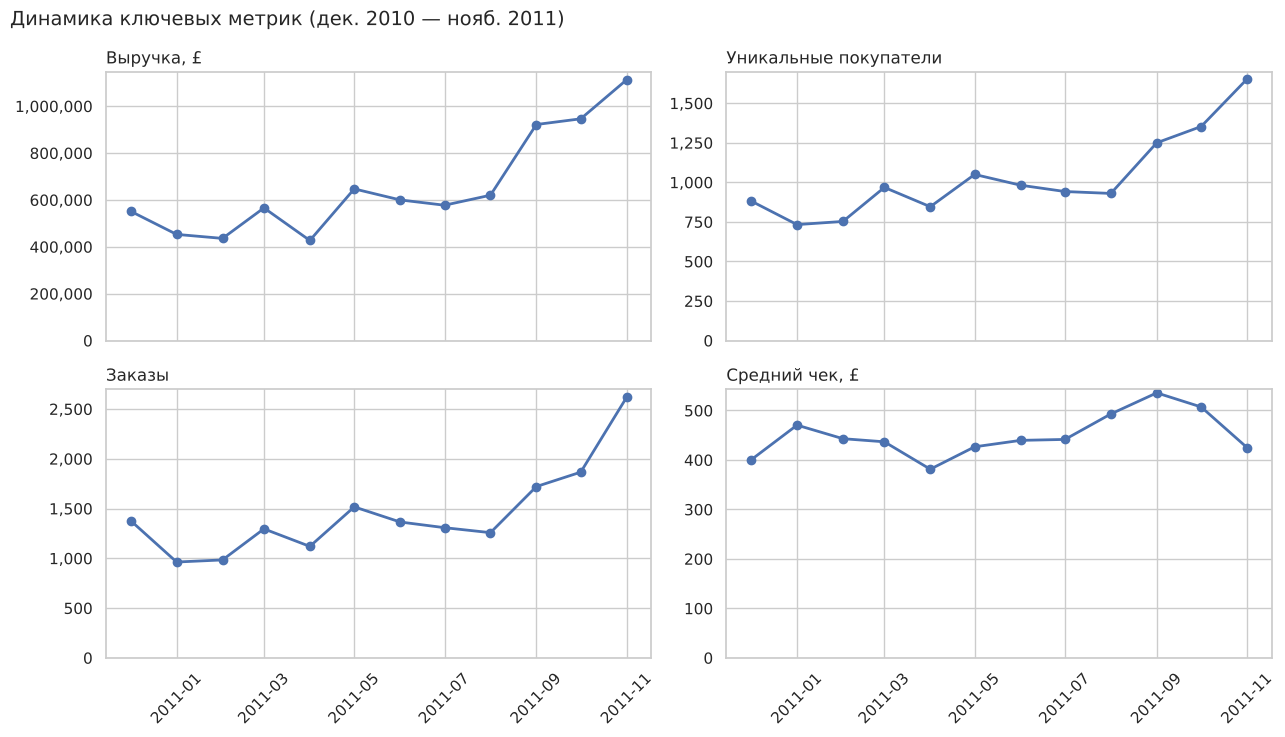

In [6]:
m = monthly[monthly.month < "2011-12"].copy()
m["month"] = pd.to_datetime(m["month"])

fig, axes = plt.subplots(2, 2, figsize=(13, 7.5), sharex=True)
for ax, (col, title, fmt) in zip(axes.flat, [
        ("revenue", "Выручка, £", "{x:,.0f}"),
        ("customers", "Уникальные покупатели", "{x:,.0f}"),
        ("orders", "Заказы", "{x:,.0f}"),
        ("avg_order_value", "Средний чек, £", "{x:,.0f}")]):
    ax.plot(m["month"], m[col], marker="o", lw=2)
    ax.set_title(title, fontsize=12, loc="left")
    ax.yaxis.set_major_formatter(mtick.StrMethodFormatter(fmt))
    ax.set_ylim(bottom=0)
for ax in axes[1]:
    ax.tick_params(axis="x", rotation=45)
fig.suptitle("Динамика ключевых метрик (дек. 2010 — нояб. 2011)", fontsize=14, x=0.01, ha="left")
fig.tight_layout()
fig.savefig("images/monthly_metrics.png", dpi=120, bbox_inches="tight")

In [7]:
first, last = m.iloc[0], m.iloc[-1]
sep_nov = m[m.month >= "2011-09"].revenue.sum() / m.revenue.sum()
print(f"Рост выручки дек.2010 → нояб.2011: {last.revenue/first.revenue - 1:+.0%}")
print(f"Рост числа покупателей: {last.customers/first.customers - 1:+.0%}, среднего чека: {last.avg_order_value/first.avg_order_value - 1:+.0%}")
print(f"Доля сентября–ноября в выручке года: {sep_nov:.0%}")

Рост выручки дек.2010 → нояб.2011: +102%
Рост числа покупателей: +87%, среднего чека: +6%
Доля сентября–ноября в выручке года: 38%

**Вывод.** За 11 месяцев выручка выросла примерно в 2 раза (+102%), и рост почти целиком обеспечен **числом покупателей** (+87%), а не средним чеком (+6%). Бизнес сильно сезонный: сентябрь–ноябрь дают **38% годовой выручки** (подготовка к Рождеству; среди клиентов много оптовиков, которые закупают подарочный товар заранее).

## 3. Когортный анализ

Когорта — месяц первой покупки клиента. Retention месяца N — доля клиентов когорты, совершивших хотя бы одну покупку через N месяцев после первой.

Запрос: [`sql/02_cohort_retention.sql`](sql/02_cohort_retention.sql).

In [8]:
cohorts = run_sql("02_cohort_retention.sql", con)
cohorts = cohorts[cohorts.cohort < "2011-12"]          # последняя когорта неполная
retention = cohorts.pivot(index="cohort", columns="month_number", values="retention_pct")
sizes = cohorts[cohorts.month_number == 0].set_index("cohort")["active_customers"]

# последний месяц (дек. 2011) неполный — убираем ячейки, которые на него приходятся
ret = retention.copy()
for c in ret.index:
    n_full = (pd.Period("2011-11", "M") - pd.Period(c, "M")).n
    ret.loc[c, [col for col in ret.columns if col > n_full]] = np.nan
ret.iloc[:, :7]

month_number,0,1,2,3,4,5,6
cohort,,,,,,,
2010-12,100.00,36.30,32.20,38.10,35.70,39.70,35.90
2011-01,100.00,21.30,26.90,23.20,32.20,28.60,25.20
2011-02,100.00,18.60,18.60,28.30,27.00,24.10,25.50
2011-03,100.00,14.40,24.90,19.30,22.40,16.70,26.20
2011-04,100.00,21.10,20.40,21.10,19.70,22.70,21.10
2011-05,100.00,19.40,17.30,17.30,21.10,22.90,26.40
2011-06,100.00,17.40,15.80,26.60,23.20,32.40,NaN
2011-07,100.00,17.20,20.40,22.60,27.40,NaN,NaN
2011-08,100.00,20.00,24.10,24.70,NaN,NaN,NaN


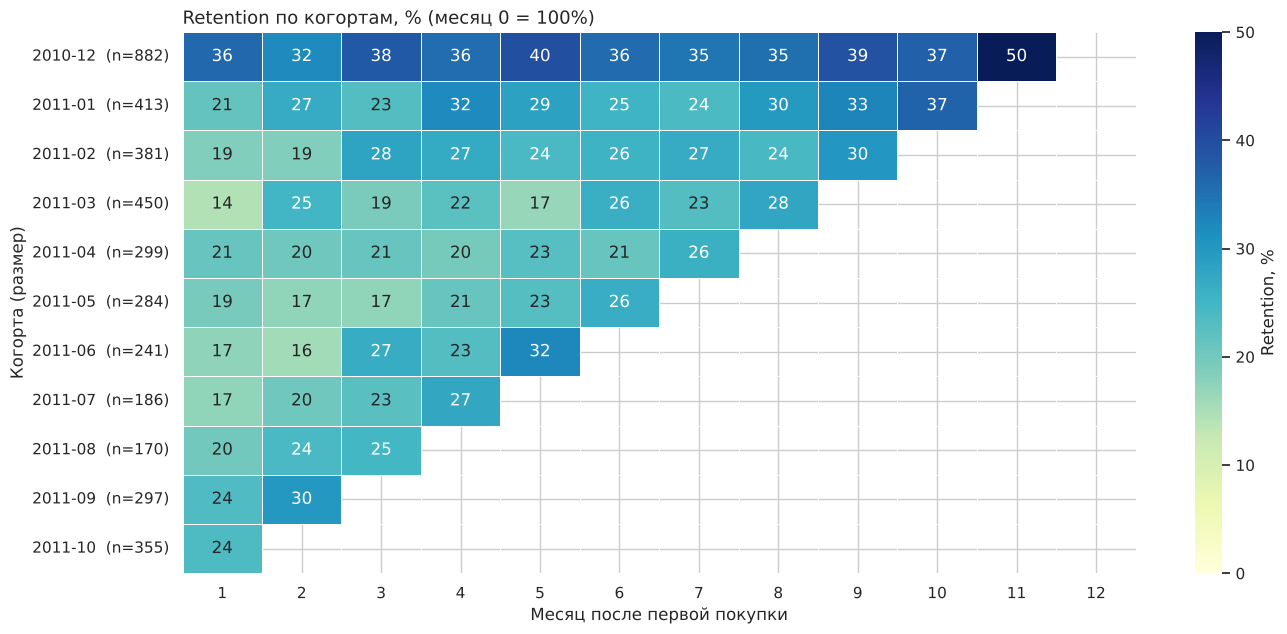

In [9]:
fig, ax = plt.subplots(figsize=(14, 6.5))
sns.heatmap(ret.iloc[:-1, 1:], annot=True, fmt=".0f", cmap="YlGnBu", vmin=0, vmax=50,
            cbar_kws={"label": "Retention, %"}, linewidths=.5, ax=ax)
ax.set_yticklabels([f"{c}  (n={sizes[c]})" for c in ret.index[:-1]], rotation=0)
ax.set_xlabel("Месяц после первой покупки")
ax.set_ylabel("Когорта (размер)")
ax.set_title("Retention по когортам, % (месяц 0 = 100%)", loc="left", fontsize=13)
fig.tight_layout()
fig.savefig("images/cohort_retention.png", dpi=120, bbox_inches="tight")

In [10]:
dec = ret.loc["2010-12"]
rest = ret.drop(index="2010-12")
weights = sizes.drop(index="2010-12")
avg_rest = rest.apply(lambda col: np.average(col.dropna(), weights=weights[col.dropna().index]) if col.notna().any() else np.nan)

summary = pd.DataFrame({"Когорта дек. 2010": dec, "Остальные когорты (взвеш. среднее)": avg_rest}).loc[1:6]
summary.index.name = "Месяц"
summary.round(1)

,Когорта дек. 2010,Остальные когорты (взвеш. среднее)
Месяц,,
1,36.30,19.60
2,32.20,22.40
3,38.10,22.70
4,35.70,24.90
5,39.70,24.00
6,35.90,25.00


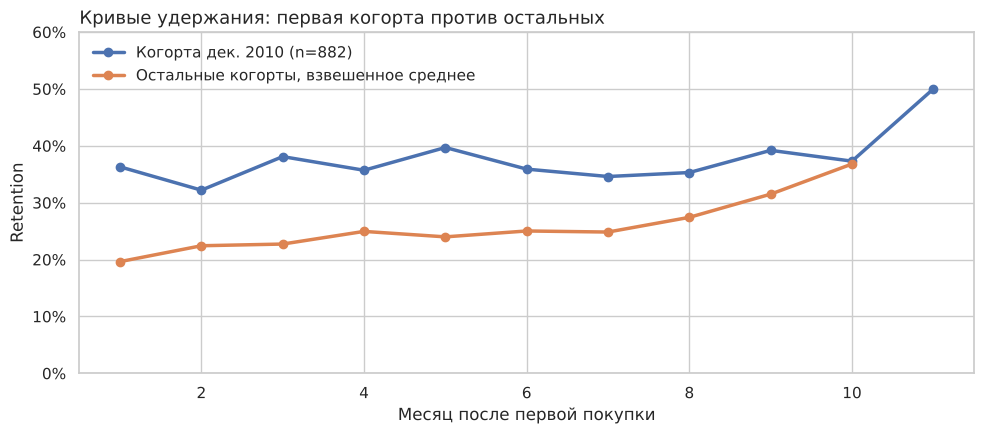

In [11]:
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(dec.index[1:12], dec.values[1:12], marker="o", lw=2.5, label="Когорта дек. 2010 (n=%d)" % sizes["2010-12"])
ax.plot(avg_rest.index[1:11], avg_rest.values[1:11], marker="o", lw=2.5, label="Остальные когорты, взвешенное среднее")
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_xlabel("Месяц после первой покупки"); ax.set_ylabel("Retention")
ax.set_ylim(0, 60); ax.legend(frameon=False)
ax.set_title("Кривые удержания: первая когорта против остальных", loc="left", fontsize=13)
fig.tight_layout()
fig.savefig("images/retention_curves.png", dpi=120, bbox_inches="tight")

**Выводы по удержанию.**
- Когорта декабря 2010 года резко выделяется: 32–40% клиентов возвращаются каждый месяц, у остальных когорт — 20–25%. Причина не в «удачном декабре»: данные начинаются с 01.12.2010, поэтому в эту когорту попали все давние клиенты, которые покупали и раньше. Это накопленная лояльная база, а не новые пользователи, и сравнивать с ней новые когорты некорректно.
- У новых клиентов главная потеря происходит сразу: во втором месяце возвращается только **~20%**. Дальше кривая не падает, а держится на уровне 22–25%: кто вернулся, тот остаётся. Значит, главный рычаг — **конверсия во вторую покупку**.
- На диагоналях тепловой карты видна сезонность: в сентябре–ноябре retention всех когорт растёт (например, когорта июня: 32% на 5-й месяц).

### Накопленная выручка на клиента (LTV) по когортам

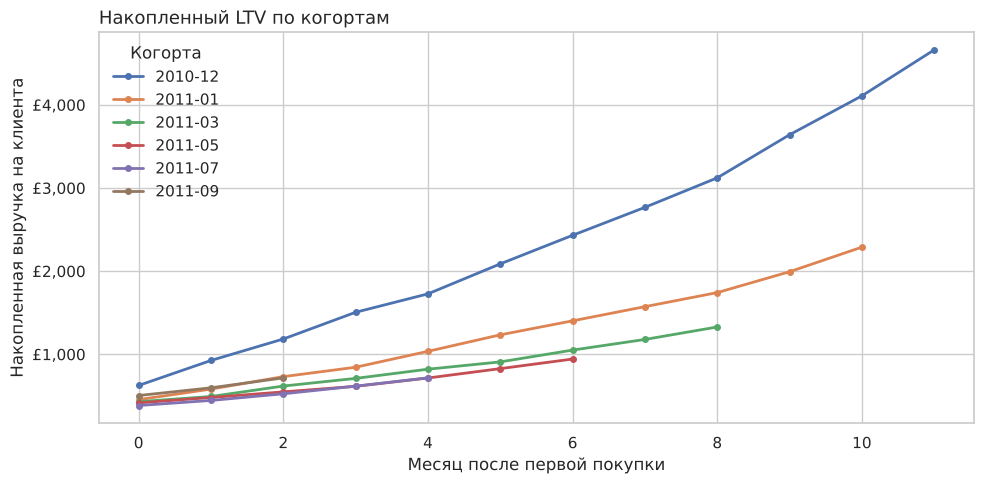

month_number,LTV месяц 0,LTV месяц 2,LTV месяц 5
cohort,,,
2010-12,625.00,"1,184.00","2,088.00"
2011-01,455.00,731.00,"1,234.00"
2011-02,410.00,582.00,893.00
2011-03,430.00,618.00,909.00
2011-04,396.00,573.00,838.00
2011-05,416.00,548.00,828.00
2011-06,382.00,495.00,893.00
2011-07,384.00,525.00,NaN
2011-08,462.00,762.00,NaN


In [12]:
df["cohort"] = df.groupby("CustomerID")["InvoiceDate"].transform("min").dt.to_period("M")
df["month_number"] = (df["InvoiceDate"].dt.to_period("M") - df["cohort"]).apply(lambda x: x.n)

ltv = (df[df.InvoiceDate < "2011-12-01"]
       .groupby(["cohort", "month_number"])["Revenue"].sum()
       .unstack().cumsum(axis=1)
       .div(df.groupby("cohort")["CustomerID"].nunique(), axis=0))

fig, ax = plt.subplots(figsize=(10, 5))
for c in ["2010-12", "2011-01", "2011-03", "2011-05", "2011-07", "2011-09"]:
    s = ltv.loc[pd.Period(c, "M")].dropna()
    ax.plot(s.index, s.values, marker="o", ms=4, lw=2, label=c)
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("£{x:,.0f}"))
ax.set_xlabel("Месяц после первой покупки"); ax.set_ylabel("Накопленная выручка на клиента")
ax.legend(title="Когорта", frameon=False)
ax.set_title("Накопленный LTV по когортам", loc="left", fontsize=13)
fig.tight_layout()
fig.savefig("images/cohort_ltv.png", dpi=120, bbox_inches="tight")

ltv_tbl = ltv[[0, 2, 5]].rename(columns={0: "LTV месяц 0", 2: "LTV месяц 2", 5: "LTV месяц 5"})
ltv_tbl.index = ltv_tbl.index.astype(str)
ltv_tbl.round(0)

**Вывод.** Первая покупка нового клиента приносит в среднем £400–450, а за 5 месяцев повторные покупки **удваивают** выручку на клиента (≈ £830–910 у когорт февраля–июня). Средний клиент давней базы (когорта дек. 2010) за то же время приносит £2 088 — в 2,3 раза больше. Каждый новый клиент, ставший постоянным, многократно окупает затраты на удержание.

## 4. RFM-сегментация

- **R (Recency)** — сколько дней прошло с последней покупки;
- **F (Frequency)** — число заказов;
- **M (Monetary)** — сумма покупок.

Каждой метрике ставим балл 1–5 по квинтилям, затем объединяем клиентов в сегменты по R и F (стандартная схема RFM-сегментов). Запрос: [`sql/03_rfm_base.sql`](sql/03_rfm_base.sql).

In [13]:
rfm = run_sql("03_rfm_base.sql", con)
rfm["R"] = pd.qcut(rfm.recency_days, 5, labels=[5, 4, 3, 2, 1]).astype(int)
rfm["F"] = pd.qcut(rfm.frequency.rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm["M"] = pd.qcut(rfm.monetary, 5, labels=[1, 2, 3, 4, 5]).astype(int)

def segment(r, f):
    if r >= 4 and f >= 4:  return "Чемпионы"
    if r >= 3 and f >= 3:  return "Лояльные"
    if r >= 4 and f <= 2:  return "Новые / перспективные"
    if r == 3 and f <= 2:  return "Требуют внимания"
    if r <= 2 and f >= 4:  return "Нельзя потерять"
    if r <= 2 and f == 3:  return "В зоне риска"
    return "Спящие / потерянные"

rfm["segment"] = [segment(r, f) for r, f in zip(rfm.R, rfm.F)]
rfm.head()

,customer_id,recency_days,frequency,monetary,R,F,M,segment
0,12347,3,7,"4,310.00",5,5,5,Чемпионы
1,12348,76,4,"1,437.24",2,4,4,Нельзя потерять
2,12349,19,1,"1,457.55",4,1,4,Новые / перспективные
3,12350,311,1,294.40,1,1,2,Спящие / потерянные
4,12352,37,5,"1,125.28",3,4,4,Лояльные


In [14]:
seg = (rfm.groupby("segment")
          .agg(customers=("customer_id", "count"), revenue=("monetary", "sum"),
               avg_recency=("recency_days", "mean"), avg_frequency=("frequency", "mean"),
               avg_monetary=("monetary", "mean"))
          .sort_values("revenue", ascending=False))
seg["доля клиентов, %"] = 100 * seg.customers / seg.customers.sum()
seg["доля выручки, %"] = 100 * seg.revenue / seg.revenue.sum()
seg.round(1)

,customers,revenue,avg_recency,avg_frequency,avg_monetary,"доля клиентов, %","доля выручки, %"
segment,,,,,,,
Чемпионы,1119,"5,635,294.10",13.60,9.90,"5,036.00",25.90,68.70
Лояльные,824,"1,128,426.50",37.90,3.60,"1,369.40",19.10,13.80
Спящие / потерянные,1076,"445,774.90",218.30,1.10,414.30,24.90,5.40
Нельзя потерять,283,"430,532.70",138.20,4.80,"1,521.30",6.50,5.30
В зоне риска,366,"274,437.60",162.90,2.30,749.80,8.50,3.30
Требуют внимания,345,"156,550.20",53.30,1.10,453.80,8.00,1.90
Новые / перспективные,308,"128,407.80",18.90,1.20,416.90,7.10,1.60


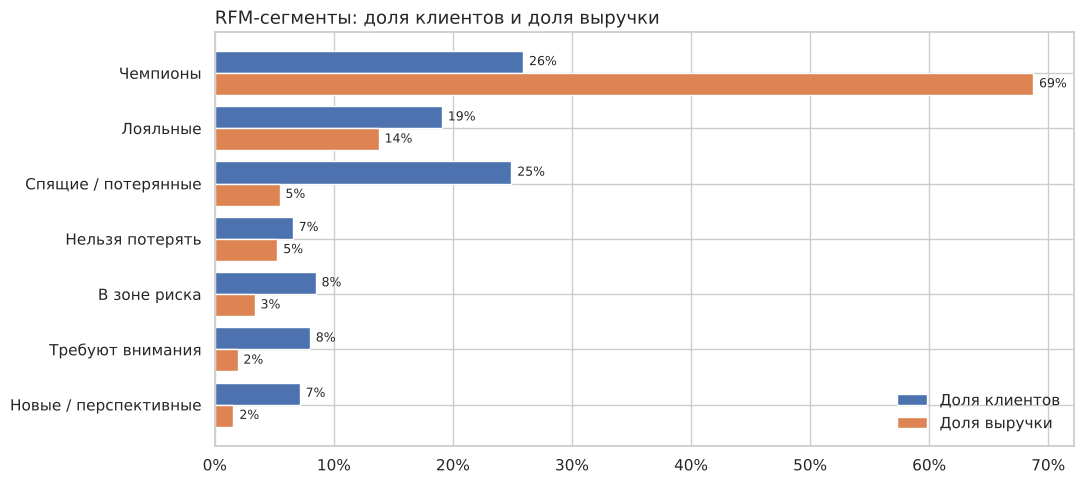

In [15]:
order = seg.index.tolist()
fig, ax = plt.subplots(figsize=(11, 5))
y = np.arange(len(order))
ax.barh(y - 0.2, seg["доля клиентов, %"], height=0.4, label="Доля клиентов")
ax.barh(y + 0.2, seg["доля выручки, %"], height=0.4, label="Доля выручки")
ax.set_yticks(y, order); ax.invert_yaxis()
ax.xaxis.set_major_formatter(mtick.PercentFormatter())
for i, (c, r) in enumerate(zip(seg["доля клиентов, %"], seg["доля выручки, %"])):
    ax.text(c + 0.5, i - 0.2, f"{c:.0f}%", va="center", fontsize=9)
    ax.text(r + 0.5, i + 0.2, f"{r:.0f}%", va="center", fontsize=9)
ax.legend(frameon=False, loc="lower right")
ax.set_title("RFM-сегменты: доля клиентов и доля выручки", loc="left", fontsize=13)
fig.tight_layout()
fig.savefig("images/rfm_segments.png", dpi=120, bbox_inches="tight")

Топ-1% клиентов дают 30% выручки, топ-20% — 73%

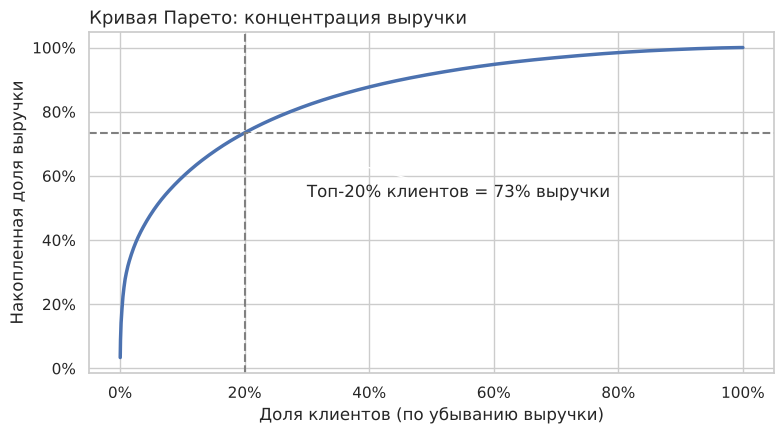

In [16]:
s = rfm.monetary.sort_values(ascending=False).reset_index(drop=True)
cum = s.cumsum() / s.sum()
top20 = cum.iloc[int(len(s) * 0.2) - 1]
top1 = cum.iloc[int(len(s) * 0.01) - 1]

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(np.arange(1, len(s) + 1) / len(s) * 100, cum * 100, lw=2.5)
ax.axvline(20, ls="--", c="grey"); ax.axhline(top20 * 100, ls="--", c="grey")
ax.annotate(f"Топ-20% клиентов = {top20:.0%} выручки", xy=(20, top20 * 100), xytext=(30, top20 * 100 - 20),
            arrowprops=dict(arrowstyle="->"))
ax.xaxis.set_major_formatter(mtick.PercentFormatter()); ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_xlabel("Доля клиентов (по убыванию выручки)"); ax.set_ylabel("Накопленная доля выручки")
ax.set_title("Кривая Парето: концентрация выручки", loc="left", fontsize=13)
fig.tight_layout()
fig.savefig("images/pareto.png", dpi=120, bbox_inches="tight")
print(f"Топ-1% клиентов дают {top1:.0%} выручки, топ-20% — {top20:.0%}")

**Выводы по сегментам.**
- **Чемпионы** — 26% клиентов дают **69% выручки**; в целом топ-20% клиентов приносят 73% выручки, топ-1% — 30%. Выручка сильно сконцентрирована: потеря даже нескольких крупных клиентов заметно ударит по бизнесу.
- **«Нельзя потерять» и «В зоне риска»** — 15% клиентов (≈650 человек), которые раньше покупали часто, но давно не возвращались. На них приходится 8,6% выручки — это главный кандидат для win-back кампании.
- **Спящие / потерянные** — четверть базы, но всего 5% выручки: тратить на них большой бюджет нецелесообразно.

## 5. Топ товаров

Запрос с оконной функцией: [`sql/04_top_products.sql`](sql/04_top_products.sql).

In [17]:
run_sql("04_top_products.sql", con)

,stock_code,description,units,revenue,revenue_share_pct,buyers
0,22423,REGENCY CAKESTAND 3 TIER,11683,"134,365.00",1.64,866
1,85123A,WHITE HANGING HEART T-LIGHT HOLDER,32124,"88,896.00",1.08,852
2,85099B,JUMBO BAG RED RETROSPOT,43005,"79,650.00",0.97,632
3,47566,PARTY BUNTING,14937,"67,293.00",0.82,706
4,84879,ASSORTED COLOUR BIRD ORNAMENT,35197,"56,301.00",0.69,676
5,23084,RABBIT NIGHT LIGHT,27087,"51,114.00",0.62,447
6,79321,CHILLI LIGHTS,9549,"45,815.00",0.56,203
7,22086,PAPER CHAIN KIT 50'S CHRISTMAS,14743,"40,419.00",0.49,609
8,21137,BLACK RECORD COVER FRAME,11377,"38,956.00",0.48,137
9,22197,SMALL POPCORN HOLDER,48923,"37,031.00",0.45,405


## 6. Итоги и рекомендации

| # | Наблюдение | Рекомендация |
|---|---|---|
| 1 | Во второй месяц возвращается лишь ~20% новых клиентов, но вернувшиеся остаются надолго | Цепочка писем и персональный промокод после первого заказа; цель — +5 п.п. к retention 1-го месяца |
| 2 | 26% клиентов («Чемпионы») дают 69% выручки | Программа лояльности / персональный менеджер для крупнейших клиентов, контроль их оттока как отдельной метрики |
| 3 | 15% клиентов с высокой частотой покупок перестали заказывать | Win-back кампания для сегментов «Нельзя потерять» и «В зоне риска» с персональными предложениями |
| 4 | Сентябрь–ноябрь = 38% годовой выручки | Закупки, склад и маркетинговый бюджет готовить к августу; запускать реактивацию до начала сезона |
| 5 | Рост выручки идёт за счёт новых клиентов, а не среднего чека | Тестировать механики роста чека: наборы товаров, пороги бесплатной доставки, рекомендации |

**Ограничения:** у ~25% строк нет `CustomerID` (они не вошли в анализ); данные покрывают только 1 год, поэтому когорта дек. 2010 смешивает новых и давних клиентов; отмены сопоставлялись с покупками по клиенту, товару и количеству, частичные отмены не учитывались.